# 3.7 Walking access by neighbourhood income and housing type (H-b)

**H-b (proposal):** walking access to childcare differs by neighbourhood socio-economic status, with
lower-income estates and estates dominated by 1-3-room flats being worse served.

- H0: median walk time to the nearest centre (and listed fee, and supply pressure) does not differ
  across planning-area income terciles or across terciles of the share of 1-3-room flats.
- H1: at least one of them does.

The test is descriptive and rank-based because the three measures are skewed: medians by tercile,
Spearman rank correlations with the two SES measures (with a two-sided p-value), and a Kruskal-Wallis
test across the three terciles. The unit is the HDB subzone with at least 100 children aged 0-6 and a
planning-area income (137 of 159). The tercile figure is the H-b slide of the deck
(`scripts/make_deck_figures.py`, Minh); the correlations were quoted in its footnote and are computed
here in full.

**Inputs**
- `output/hdb_blocks.gpkg`, layer `subzone_pressure` (3.7): walk time, listed-fee median, `pressure_base`, planning-area income. *From a clean checkout, run 3.7 before this notebook.*
- `output/subzone_stats.csv` (stage 1): `pct_1to3room`.

**Outputs**
- `figures/hb_access_by_ses.png`.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "bt4015").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from bt4015.paths import DATA, OUT, FIG, LARGE

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio
from scipy.stats import kruskal, spearmanr

from bt4015.maps import BLUE, INK, INK2, INK3, tidy, use_deck_style

use_deck_style()
MIN_CHILDREN = 100   # subzones with fewer children 0-6 rest on a handful of blocks (decision 2026-11-02)
METRICS = [("walk_nearest_min_cw", "Median walk to nearest centre (min)"),
           ("median_fee_listed", "Median listed full-day fee (S$)"),
           ("pressure_base", "Median children per reachable centre")]
GROUPS = ["Income tercile (planning area)", "Share of 1–3-room flats (tercile)"]

## 1. Subzone table with the two SES measures

Income is the planning-area estimated median household income (3.2's interpolation, attached in stage
1 as `pa_median_income_sgd`); housing type is the share of 1-3-room flats among the subzone's HDB
dwelling units. Each is cut into terciles over the analysed subzones.

In [2]:
# 1. Pressure layer (walk time, fee, pressure, income) joined to the flat-type share.
sp = pyogrio.read_dataframe(OUT / "hdb_blocks.gpkg", layer="subzone_pressure")
st = pd.read_csv(OUT / "subzone_stats.csv")[["SUBZONE_C", "pct_1to3room", "child_density_0_6_km2"]]
h = sp[sp["has_hdb"] & (sp["children_0_6"] >= MIN_CHILDREN) & sp["pressure_base"].notna()].merge(st, on="SUBZONE_C").reset_index(drop=True)
print(f"HDB subzones with >= {MIN_CHILDREN} children 0-6 and a pressure value: {len(h)}")

# 2. Keep subzones whose planning area has an income estimate (22 central/private-estate areas have none).
i = h[h["pa_median_income_sgd"].notna()].copy()
print(f"with planning-area income: {len(i)} (dropped {len(h) - len(i)}: "
      + ", ".join(sorted(h.loc[h['pa_median_income_sgd'].isna(), 'PLN_AREA_N'].str.title().unique())) + ")")

# 3. Terciles of each SES measure.
i[GROUPS[0]] = pd.qcut(i["pa_median_income_sgd"], 3, labels=["low", "mid", "high"])
i[GROUPS[1]] = pd.qcut(i["pct_1to3room"], 3, labels=["low", "mid", "high"])
for grp, col in zip(GROUPS, ["pa_median_income_sgd", "pct_1to3room"]):
    edges = i.groupby(grp, observed=True)[col].agg(["min", "max", "size"])
    print(f"\n{grp}:\n{edges.round(2).to_string()}")

HDB subzones with >= 100 children 0-6 and a pressure value: 140
with planning-area income: 137 (dropped 3: Tengah)

Income tercile (planning area):
                                   min      max  size
Income tercile (planning area)                       
low                             3500.0   6500.0    58
mid                             7500.0   7500.0    36
high                            8500.0  16250.0    43

Share of 1–3-room flats (tercile):
                                     min    max  size
Share of 1–3-room flats (tercile)                    
low                                 0.00  23.20    46
mid                                23.45  43.55    45
high                               43.93  97.48    46


## 2. Medians by tercile

Walk time is flat at about 3 minutes in every tercile, the listed fee is S$650 (the anchor-operator
rate) in every tercile, and pressure does not line up with either SES measure.

In [3]:
# 1. Median of each metric within each tercile of each SES measure.
rows = []
for grp in GROUPS:
    for col, lab in METRICS:
        med = i.groupby(grp, observed=True)[col].median()
        rows.append({"grouping": grp, "metric": lab, **{f"{k}": round(v, 1) for k, v in med.items()}})
medians = pd.DataFrame(rows)
print(medians.to_string(index=False))

                         grouping                               metric   low   mid  high
   Income tercile (planning area)  Median walk to nearest centre (min)   3.2   3.3   2.9
   Income tercile (planning area)      Median listed full-day fee (S$) 650.0 650.0 650.0
   Income tercile (planning area) Median children per reachable centre  91.2 112.7 111.0
Share of 1–3-room flats (tercile)  Median walk to nearest centre (min)   2.9   3.2   3.2
Share of 1–3-room flats (tercile)      Median listed full-day fee (S$) 650.0 650.0 630.0
Share of 1–3-room flats (tercile) Median children per reachable centre 119.9 100.5  95.2


## 3. Rank correlations and Kruskal-Wallis tests

Spearman rho of each metric against the continuous SES measure (two-sided p from `scipy`), and the
Kruskal-Wallis H test for a difference in location across the three terciles.

In [4]:
# 1. Spearman correlations with the continuous SES measures.
tests = []
for ses, grp in zip(["pa_median_income_sgd", "pct_1to3room"], GROUPS):
    for col, lab in METRICS:
        ok = i[[ses, col]].dropna()
        rho, p_rho = spearmanr(ok[ses], ok[col])
        samples = [g[col].dropna().to_numpy() for _, g in i.groupby(grp, observed=True)]
        H, p_kw = kruskal(*samples)
        tests.append({"SES measure": ses, "metric": col, "n": len(ok), "spearman_rho": round(rho, 3),
                      "spearman_p": round(p_rho, 4), "kruskal_H": round(H, 2), "kruskal_p": round(p_kw, 4)})
tests = pd.DataFrame(tests)
print(tests.to_string(index=False))
income_walk = tests.loc[tests["SES measure"].eq("pa_median_income_sgd") & tests["metric"].eq("walk_nearest_min_cw")].iloc[0]
income_fee = tests.loc[tests["SES measure"].eq("pa_median_income_sgd") & tests["metric"].eq("median_fee_listed")].iloc[0]
income_pressure = tests.loc[tests["SES measure"].eq("pa_median_income_sgd") & tests["metric"].eq("pressure_base")].iloc[0]
print(f"\nSpearman, income vs walk {income_walk['spearman_rho']:+.2f} (p {income_walk['spearman_p']:.3f}); "
      f"vs fee {income_fee['spearman_rho']:+.2f} (p {income_fee['spearman_p']:.3f}); "
      f"vs pressure {income_pressure['spearman_rho']:+.2f} (p {income_pressure['spearman_p']:.3f})")

         SES measure              metric   n  spearman_rho  spearman_p  kruskal_H  kruskal_p
pa_median_income_sgd walk_nearest_min_cw 137        -0.161      0.0609       8.62     0.0134
pa_median_income_sgd   median_fee_listed 137        -0.038      0.6632       0.57     0.7531
pa_median_income_sgd       pressure_base 137         0.098      0.2529       3.91     0.1415
        pct_1to3room walk_nearest_min_cw 137         0.228      0.0073       5.29     0.0709
        pct_1to3room   median_fee_listed 137        -0.048      0.5737       0.62     0.7343
        pct_1to3room       pressure_base 137        -0.185      0.0306       5.38     0.0679

Spearman, income vs walk -0.16 (p 0.061); vs fee -0.04 (p 0.663); vs pressure +0.10 (p 0.253)


## 4. Figure

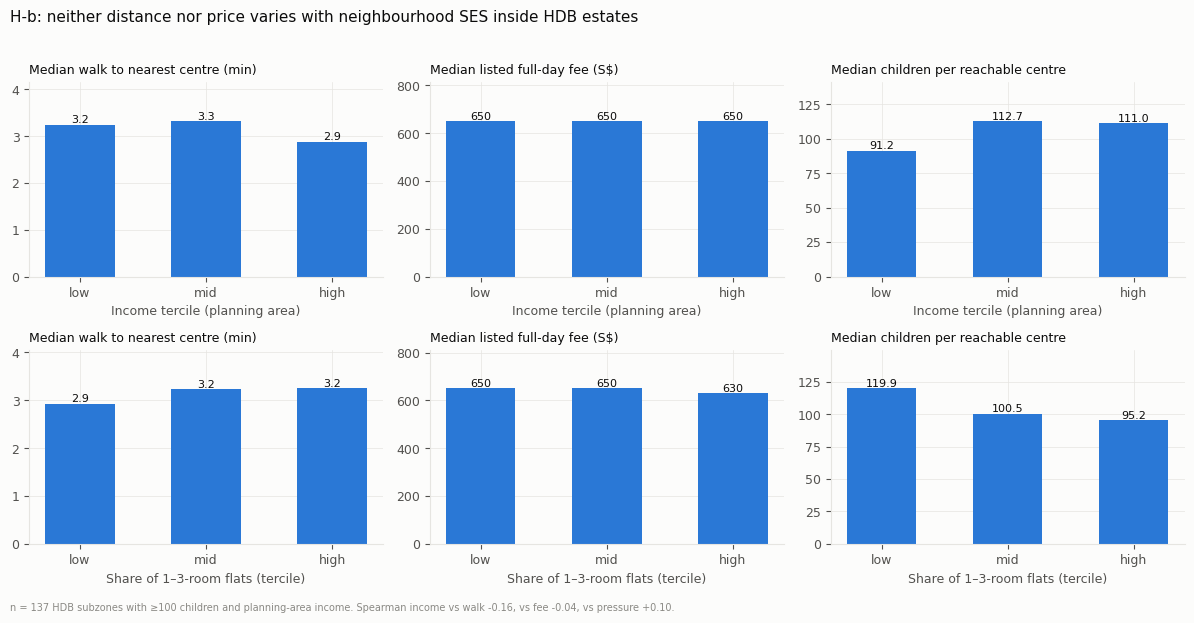

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
for r_, grp in enumerate(GROUPS):
    for c_, (col, lab) in enumerate(METRICS):
        ax = axes[r_, c_]
        med = i.groupby(grp, observed=True)[col].median()
        ax.bar(med.index.astype(str), med.values, color=BLUE, width=0.55)
        for k, v in enumerate(med.values):
            ax.text(k, v, f"{v:,.1f}" if col != "median_fee_listed" else f"{v:,.0f}", ha="center", va="bottom", fontsize=8, color=INK)
        ax.set_ylim(0, med.max() * 1.25)
        ax.set_title(lab, loc="left", fontsize=9, color=INK)
        ax.set_xlabel(grp)
        tidy(ax)
fig.suptitle("H-b: neither distance nor price varies with neighbourhood SES inside HDB estates", x=0.01, ha="left", fontsize=11)
fig.text(0.01, 0.01, f"n = {len(i)} HDB subzones with ≥100 children and planning-area income. Spearman income vs walk "
         f"{income_walk['spearman_rho']:+.2f}, vs fee {income_fee['spearman_rho']:+.2f}, vs pressure {income_pressure['spearman_rho']:+.2f}.",
         fontsize=7, color=INK3)
fig.tight_layout(rect=(0, 0.03, 1, 0.96))
fig.savefig(FIG / "hb_access_by_ses.png", dpi=170)
plt.show()

## 5. Verdict

**H0 is not rejected in any practically meaningful sense for walking access.** Median walk time is
about 3 minutes in every tercile of both SES measures. Two of the rank tests do reach 5%: walk time
against income (Kruskal-Wallis p = 0.013, Spearman rho = -0.16) and against the share of 1-3-room
flats (Spearman rho = +0.23, Kruskal-Wallis p = 0.07). Both are tiny: the high-income tercile walks
2.9 minutes against 3.2-3.3 for the others, and the 1-3-room-heavy tercile walks 3.2 against 2.9. A
difference of 20 seconds, inside a network where almost every block is within 10 minutes of a
centre, is not the SES gap the hypothesis describes, and the income effect runs the opposite way
(richer areas walk slightly *less*). Inside HDB estates, distance does not sort by socio-economic
status.

**Fees do not differ inside the HDB estates.** The listed full-day fee is S$650 in every tercile
(S$630 in the 1-3-room-heavy tercile), because the anchor-operator rate dominates every HDB town;
the correlations with both SES measures are near zero and not significant. The income gradient in
fees that 3.1-3.3 find is a *between*-planning-area pattern driven by the private-estate central
areas (Tanglin, Newton, River Valley, Downtown Core), which have no HDB subzones with 100 children
and so are not in this table.

Supply pressure (3.7) is the only measure with any SES signal, and it runs the other way from the
hypothesis: pressure is higher where the 1-3-room share is *lower* (rho = -0.19, p = 0.03), i.e. in
the newest towns (Tengah, Punggol, Tampines North), not the oldest or poorest.

In [6]:
print(f"written: {FIG.relative_to(ROOT)}/hb_access_by_ses.png (n = {len(i)} subzones)")

written: figures/hb_access_by_ses.png (n = 137 subzones)
